# [GĐ2] 04a – Huấn luyện BiLSTM phát hiện đánh giá toxic

Notebook này thực hiện 5 bước đầu của GĐ2:

1. Xây dựng **Vocab**, ma trận **Word Embeddings** và **DataLoader**
2. Thiết kế mạng **BiLSTM 2 chiều + Dropout** (PyTorch)
3. Cấu hình **`BCEWithLogitsLoss(pos_weight=15.0)`**
4. Huấn luyện 8–10 epoch, lưu `results/bilstm_best_model.pt`
5. Vẽ learning curve `results/4_bilstm_learning_curve.png`

Bước 6 (xuất dự đoán) nằm ở `04b_bilstm_predict.ipynb`.

**Cấu trúc thư mục cần có:**
```
project/
├── data/        train.csv, val.csv, test.csv
├── embeddings/  (tuỳ chọn) file PhoW2V word-level .txt
├── src/         bilstm_utils.py
├── notebooks/   04a_bilstm_train.ipynb, 04b_bilstm_predict.ipynb
└── results/
```

In [1]:
import os, sys, json, time
sys.path.insert(0, os.path.abspath(".."))      # để import được thư mục src/

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from src.bilstm_utils import (
    set_seed, Vocab, tokenize, make_loader, build_embedding_matrix,
    BiLSTMClassifier, count_parameters, train_one_epoch, predict_proba,
    compute_metrics, find_best_threshold, plot_learning_curve,
    save_checkpoint, load_checkpoint,
)
print("PyTorch:", torch.__version__)

PyTorch: 2.15.0+cpu


## 0. Cấu hình

Ghi chú về các lựa chọn (dựa trên phân tích dữ liệu):

- **`TEXT_COL = noi_dung_tien_xu_ly`**: cột đã tách từ (từ ghép nối bằng `_`), khớp với PhoW2V word-level.
- **`MAX_LEN = 128`**: câu toxic dài hơn hẳn câu thường (trung vị ~40 từ so với ~10 từ). 128 giữ trọn khoảng 95% câu toxic; cắt ngắn hơn sẽ mất tín hiệu.
- **`POS_WEIGHT = 15.0`** theo kế hoạch. Tỉ lệ thực tế trên train là 5925/123 ≈ 48, nên 15 là mức "nhẹ tay". Có thể thử thêm 25–48 để so sánh.
- **`SELECT_METRIC = "pr_auc"`**: tập val chỉ có **17 mẫu toxic**, nên F1 ở ngưỡng 0.5 dao động rất mạnh giữa các epoch. PR-AUC không phụ thuộc ngưỡng và ổn định hơn để chọn best model. Ngưỡng được tối ưu riêng sau khi train. Đổi thành `"f1_toxic"` nếu muốn bám sát kế hoạch.
- **Không dùng `so_sao` làm đặc trưng**: gần như mọi mẫu toxic đều 1–2 sao, nên mô hình sẽ học "đường tắt" theo số sao thay vì nội dung.

In [2]:
CFG = {
    # --- đường dẫn ---
    "DATA_DIR": "../data",
    "RESULTS_DIR": "../results",
    "EMBEDDING_PATH": "../embeddings/word2vec_vi_words_100dims.txt",  # PhoW2V word-level 100d; không có file -> fallback
    # --- dữ liệu ---
    "TEXT_COL": "noi_dung_tien_xu_ly",
    "LABEL_COL": "label",
    "MAX_LEN": 128,
    "MIN_FREQ": 2,
    # --- mô hình ---
    "EMBED_DIM": 300,          # bị ghi đè bởi dim của file pretrained nếu có
    "FREEZE_EMBEDDING": False,
    "HIDDEN_DIM": 128,
    "NUM_LAYERS": 1,           # 1 lớp BiLSTM là đủ cho ~6k câu; thử 2 nếu muốn so sánh
    "DROPOUT": 0.5,
    # --- huấn luyện ---
    "BATCH_SIZE": 32,
    "LR": 1e-3,
    "WEIGHT_DECAY": 1e-5,
    "EPOCHS": 10,
    "PATIENCE": 3,             # early stopping
    "POS_WEIGHT": 15.0,
    "SELECT_METRIC": "pr_auc", # "pr_auc" hoặc "f1_toxic"
    "SEED": 42,
}

os.makedirs(CFG["RESULTS_DIR"], exist_ok=True)
MODEL_PATH   = os.path.join(CFG["RESULTS_DIR"], "bilstm_best_model.pt")
VOCAB_PATH   = os.path.join(CFG["RESULTS_DIR"], "bilstm_vocab.pkl")
CURVE_PATH   = os.path.join(CFG["RESULTS_DIR"], "4_bilstm_learning_curve.png")
HISTORY_PATH = os.path.join(CFG["RESULTS_DIR"], "bilstm_history.csv")

set_seed(CFG["SEED"])
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cpu


## 1. Đọc dữ liệu và kiểm tra nhanh

In [3]:
train_df = pd.read_csv(os.path.join(CFG["DATA_DIR"], "train.csv"))
val_df   = pd.read_csv(os.path.join(CFG["DATA_DIR"], "val.csv"))
test_df  = pd.read_csv(os.path.join(CFG["DATA_DIR"], "test.csv"))

for name, df in [("train", train_df), ("val", val_df), ("test", test_df)]:
    df[CFG["TEXT_COL"]] = df[CFG["TEXT_COL"]].fillna("").astype(str)
    n_tox = int(df[CFG["LABEL_COL"]].sum())
    src = df["nguon_nhan"].unique().tolist() if "nguon_nhan" in df else "-"
    print(f"{name:5s}: {len(df):5d} dòng | toxic = {n_tox:3d} ({n_tox/len(df):.2%}) | nguồn nhãn = {src}")

lens = train_df[CFG["TEXT_COL"]].str.split().str.len()
print("\nĐộ dài (số từ) trên train theo nhãn:")
print(lens.groupby(train_df[CFG["LABEL_COL"]]).describe(percentiles=[.5, .9, .95]).round(1))
print(f"\nTỉ lệ câu bị cắt với MAX_LEN={CFG['MAX_LEN']}: {(lens > CFG['MAX_LEN']).mean():.2%}")

train:  6048 dòng | toxic = 123 (2.03%) | nguồn nhãn = ['semi_auto']
val  :   879 dòng | toxic =  17 (1.93%) | nguồn nhãn = ['semi_auto']
test :  2000 dòng | toxic =  40 (2.00%) | nguồn nhãn = ['human_consensus']

Độ dài (số từ) trên train theo nhãn:
        count  mean   std  min   50%   90%    95%    max
label                                                   
0      5925.0  15.8  19.4  1.0  10.0  33.0   47.0  375.0
1       123.0  47.8  37.2  4.0  40.0  90.8  121.3  200.0

Tỉ lệ câu bị cắt với MAX_LEN=128: 0.48%


> **Lưu ý:** nhãn train/val là `semi_auto` (bán tự động), còn test là `human_consensus` (người gán, đồng thuận). Tức là train/val có thể có nhiễu nhãn, còn test là "chuẩn vàng". Điểm trên test có thể thấp hơn val, đây là điều nên nêu trong báo cáo.

## 2. Xây dựng Vocab (chỉ trên tập train)

In [4]:
vocab = Vocab(min_freq=CFG["MIN_FREQ"]).build(train_df[CFG["TEXT_COL"]])
vocab.save(VOCAB_PATH)

print("Kích thước vocab:", len(vocab))
print("20 từ phổ biến:", vocab.itos[2:22])
for name, df in [("train", train_df), ("val", val_df), ("test", test_df)]:
    print(f"OOV rate {name}: {vocab.oov_rate(df[CFG['TEXT_COL']]):.2%}")
print("Đã lưu vocab ->", VOCAB_PATH)

Kích thước vocab: 3182
20 từ phổ biến: ['không', 'mua', 'được', 'rất', 'có', 'máy', 'tốt', 'ổn', 'mới', 'dùng', '1', 'bị', 'sản_phẩm', 'nhưng', 'hàng', 'sử_dụng', 'bảo_hành', 'điện_máy_xanh', 'quạt', 'ngày']
OOV rate train: 3.07%
OOV rate val: 4.56%
OOV rate test: 4.92%
Đã lưu vocab -> ../results\bilstm_vocab.pkl


## 3. Ma trận Word Embeddings

Thứ tự ưu tiên:
1. **PhoW2V word-level** (khuyến nghị, đang dùng bản 100d; có thể đổi sang 300d): tải file `word2vec_vi_words_100dims` (hoặc `_300dims`) từ repo `datquocnguyen/PhoW2V` trên GitHub, giải nén vào `embeddings/`.
2. Nếu không có file: train **Word2Vec** trên tập train (cần `pip install gensim`).
3. Nếu không có gensim: khởi tạo ngẫu nhiên, embedding tự học trong lúc train (kém nhất với dữ liệu nhỏ).

In [5]:
emb_matrix, emb_dim, emb_source = build_embedding_matrix(
    vocab, dim=CFG["EMBED_DIM"], pretrained_path=CFG["EMBEDDING_PATH"],
    corpus=train_df[CFG["TEXT_COL"]], seed=CFG["SEED"],
)
CFG["EMBED_DIM"] = emb_dim
print("Nguồn embedding:", emb_source)
print("Embedding dim  :", emb_dim)

Nguồn embedding: pretrained (word2vec_vi_words_100dims.txt): 3065/3182 từ có vector (96.3%)
Embedding dim  : 100


## 4. DataLoader

In [6]:
common = dict(vocab=vocab, text_col=CFG["TEXT_COL"], label_col=CFG["LABEL_COL"],
              max_len=CFG["MAX_LEN"], batch_size=CFG["BATCH_SIZE"], seed=CFG["SEED"])
train_loader      = make_loader(train_df, shuffle=True,  **common)
train_eval_loader = make_loader(train_df, shuffle=False, **common)   # để tính F1 train
val_loader        = make_loader(val_df,   shuffle=False, **common)

ids, lengths, labels = next(iter(train_loader))
print("Batch ids    :", tuple(ids.shape))
print("Batch lengths:", lengths[:10].tolist())
print("Batch labels :", labels[:10].tolist())
print("Số batch train/val:", len(train_loader), len(val_loader))

Batch ids    : (32, 65)
Batch lengths: [53, 26, 11, 65, 12, 23, 11, 18, 20, 7]
Batch labels : [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]
Số batch train/val: 189 28


## 5. Mô hình BiLSTM 2 chiều + Dropout

In [7]:
model_config = {
    "vocab_size": len(vocab),
    "embed_dim": CFG["EMBED_DIM"],
    "hidden_dim": CFG["HIDDEN_DIM"],
    "num_layers": CFG["NUM_LAYERS"],
    "dropout": CFG["DROPOUT"],
}
model = BiLSTMClassifier(**model_config, embedding_matrix=emb_matrix,
                         freeze_embedding=CFG["FREEZE_EMBEDDING"]).to(device)
print(model)
print(f"Số tham số train được: {count_parameters(model):,}")

BiLSTMClassifier(
  (embedding): Embedding(3182, 100, padding_idx=0)
  (emb_dropout): Dropout(p=0.5, inplace=False)
  (lstm): LSTM(100, 128, batch_first=True, bidirectional=True)
  (dropout): Dropout(p=0.5, inplace=False)
  (fc): Linear(in_features=512, out_features=1, bias=True)
)
Số tham số train được: 554,233


## 6. Hàm mất mát có trọng số + Optimizer

`BCEWithLogitsLoss` tự áp dụng sigmoid bên trong, nên mô hình chỉ xuất **logit**. `pos_weight=15` nghĩa là một lỗi bỏ sót mẫu toxic bị phạt nặng gấp 15 lần.

In [8]:
criterion = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([CFG["POS_WEIGHT"]], device=device))
optimizer = torch.optim.Adam(model.parameters(), lr=CFG["LR"], weight_decay=CFG["WEIGHT_DECAY"])
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", factor=0.5, patience=1)

## 7. Huấn luyện + lưu best model

In [9]:
history = []
best_score, best_epoch, wait = -np.inf, 0, 0

for epoch in range(1, CFG["EPOCHS"] + 1):
    t0 = time.time()
    train_loss = train_one_epoch(model, train_loader, criterion, optimizer, device)

    tr_probs, tr_y, _        = predict_proba(model, train_eval_loader, device)
    val_probs, val_y, val_loss = predict_proba(model, val_loader, device, criterion)
    tr_m  = compute_metrics(tr_y, tr_probs, 0.5)
    val_m = compute_metrics(val_y, val_probs, 0.5)

    score = val_m[CFG["SELECT_METRIC"]]
    scheduler.step(score)

    history.append({
        "epoch": epoch, "train_loss": train_loss, "val_loss": val_loss,
        "train_f1_toxic": tr_m["f1_toxic"],
        "val_f1_toxic": val_m["f1_toxic"], "val_precision_toxic": val_m["precision_toxic"],
        "val_recall_toxic": val_m["recall_toxic"], "val_f1_macro": val_m["f1_macro"],
        "val_pr_auc": val_m["pr_auc"], "lr": optimizer.param_groups[0]["lr"],
    })

    flag = ""
    if score > best_score:
        best_score, best_epoch, wait = score, epoch, 0
        save_checkpoint(MODEL_PATH, model, model_config, extra={
            "epoch": epoch, "cfg": CFG, "val_metrics_at_0.5": val_m, "threshold": 0.5,
        })
        flag = "  <- best, đã lưu"
    else:
        wait += 1

    print(f"Epoch {epoch:2d} | train_loss {train_loss:.4f} | val_loss {val_loss:.4f} | "
          f"val F1 {val_m['f1_toxic']:.3f} (P {val_m['precision_toxic']:.2f} R {val_m['recall_toxic']:.2f}) | "
          f"PR-AUC {val_m['pr_auc']:.3f} | {time.time()-t0:.1f}s{flag}")

    if wait >= CFG["PATIENCE"]:
        print(f"Early stopping: {CFG['SELECT_METRIC']} không cải thiện sau {CFG['PATIENCE']} epoch.")
        break

history_df = pd.DataFrame(history)
history_df.to_csv(HISTORY_PATH, index=False)
print(f"\nBest epoch = {best_epoch}, val {CFG['SELECT_METRIC']} = {best_score:.4f}")

Epoch  1 | train_loss 0.6945 | val_loss 0.3610 | val F1 0.250 (P 0.15 R 0.71) | PR-AUC 0.239 | 23.2s  <- best, đã lưu


Epoch  2 | train_loss 0.5042 | val_loss 0.6270 | val F1 0.286 (P 0.36 R 0.24) | PR-AUC 0.264 | 22.5s  <- best, đã lưu


Epoch  3 | train_loss 0.2952 | val_loss 0.4643 | val F1 0.368 (P 0.33 R 0.41) | PR-AUC 0.328 | 29.1s  <- best, đã lưu


Epoch  4 | train_loss 0.1993 | val_loss 0.5285 | val F1 0.240 (P 0.38 R 0.18) | PR-AUC 0.406 | 26.0s  <- best, đã lưu


Epoch  5 | train_loss 0.1306 | val_loss 0.4986 | val F1 0.391 (P 0.31 R 0.53) | PR-AUC 0.351 | 22.4s


Epoch  6 | train_loss 0.0405 | val_loss 1.4504 | val F1 0.273 (P 0.60 R 0.18) | PR-AUC 0.294 | 31.0s


Epoch  7 | train_loss 0.0542 | val_loss 0.4677 | val F1 0.458 (P 0.35 R 0.65) | PR-AUC 0.388 | 31.2s
Early stopping: pr_auc không cải thiện sau 3 epoch.

Best epoch = 4, val pr_auc = 0.4058


## 8. Chọn ngưỡng phân loại trên tập val

Với dữ liệu mất cân bằng, ngưỡng 0.5 hiếm khi tối ưu. Ta nạp best model, tìm ngưỡng cho F1 lớp toxic cao nhất trên **val**, rồi lưu ngưỡng vào checkpoint để notebook 04b dùng. **Không** được chọn ngưỡng trên test.

In [10]:
best_model, ckpt = load_checkpoint(MODEL_PATH, device)
val_probs, val_y, _ = predict_proba(best_model, val_loader, device)

best_thr, best_thr_f1 = find_best_threshold(val_y, val_probs)
m05  = compute_metrics(val_y, val_probs, 0.5)
mthr = compute_metrics(val_y, val_probs, best_thr)

print(pd.DataFrame([m05, mthr], index=["ngưỡng 0.5", f"ngưỡng tối ưu {best_thr}"]).round(4).T)

ckpt["threshold"] = best_thr
ckpt["val_metrics_at_threshold"] = mthr
torch.save(ckpt, MODEL_PATH)
print(f"\nĐã cập nhật ngưỡng {best_thr} vào {MODEL_PATH}")

                 ngưỡng 0.5  ngưỡng tối ưu 0.17
threshold            0.5000              0.1700
f1_toxic             0.2400              0.4490
precision_toxic      0.3750              0.3438
recall_toxic         0.1765              0.6471
f1_macro             0.6145              0.7166
pr_auc               0.4058              0.4058
roc_auc              0.9678              0.9678
tp                   3.0000             11.0000
fp                   5.0000             21.0000
fn                  14.0000              6.0000
tn                 857.0000            841.0000

Đã cập nhật ngưỡng 0.17 vào ../results\bilstm_best_model.pt


> Val chỉ có 17 mẫu toxic, nên ngưỡng tối ưu có thể "khớp quá" với val. Nếu ngưỡng tìm được quá cực đoan (ví dụ < 0.15 hoặc > 0.9), nên cân nhắc dùng một giá trị trung dung hơn.

## 9. Learning curve

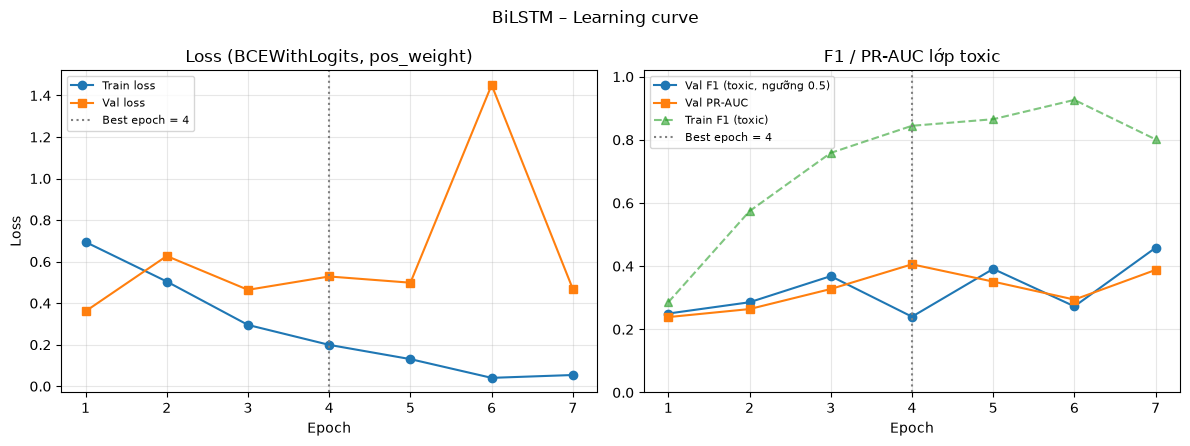

Đã lưu -> ../results\4_bilstm_learning_curve.png


In [11]:
fig = plot_learning_curve(history_df, CURVE_PATH, best_epoch=best_epoch)
plt.show()
print("Đã lưu ->", CURVE_PATH)

**Cách đọc learning curve:**
- Train loss giảm đều nhưng val loss tăng lên → overfitting. Thử tăng `DROPOUT`, giảm `HIDDEN_DIM`, hoặc bật `FREEZE_EMBEDDING`.
- Train F1 tiến tới 1.0 trong khi val F1 đứng yên → mô hình đang "học thuộc" 123 mẫu toxic.
- Val F1 nhảy lên xuống mạnh là bình thường với 17 mẫu toxic. Hãy nhìn PR-AUC để thấy xu hướng.

In [12]:
print("Các file đã tạo:")
for p in [MODEL_PATH, VOCAB_PATH, CURVE_PATH, HISTORY_PATH]:
    print(f"  {p:45s} {'OK' if os.path.exists(p) else 'THIẾU'}")

Các file đã tạo:
  ../results\bilstm_best_model.pt               OK
  ../results\bilstm_vocab.pkl                   OK
  ../results\4_bilstm_learning_curve.png        OK
  ../results\bilstm_history.csv                 OK
